
# BahaPredict — Rainfall Distribution Analysis

## M5.1 — Descriptive Statistics and Rainfall Distribution

### Objective

This analysis investigates the distribution of daily rainfall across the 17 representative locations in the Philippines.

It examines whether unusually high rainfall observations influence average daily rainfall by comparing the mean, median, percentiles, and maximum rainfall values.

The analysis builds on the processed dataset generated during M3.

**Dataset:** `data/processed/rainfall_clean.csv`

**Observation Period:** January 1, 2026 – October 31, 2026

**Geographic Scope:** 17 representative locations across the Philippines


In [73]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Locate the project root automatically
current = Path.cwd()

PROJECT_ROOT = next(
    (
        p for p in [current, *current.parents]
        if (p / "data" / "processed" / "rainfall_clean.csv").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/processed/rainfall_clean.csv"
    )

# Define project paths
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "rainfall_clean.csv"
FIGURE_DIR = PROJECT_ROOT / "output" / "figures"
ANALYSIS_DIR = PROJECT_ROOT / "output" / "analysis"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# Load dataset
df = pd.read_csv(DATA_PATH, parse_dates=["date"])

# Ensure appropriate data types
df["precipitation_mm"] = pd.to_numeric(
    df["precipitation_mm"], errors="coerce"
)

# Basic dataset information
print("BAHAPREDICT — M5 DATA VALIDATION")
print("-" * 40)

print(f"Total records: {len(df):,}")
print(f"Unique regions: {df['region'].nunique()}")
print(f"Unique locations: {df['location'].nunique()}")
print(f"Start date: {df['date'].min().date()}")
print(f"End date: {df['date'].max().date()}")

print("\nMissing values:")
print(df[["date", "region", "location", "precipitation_mm"]].isnull().sum())

print("\nDuplicate observations:")
print(df.duplicated(
    subset=["date", "latitude", "longitude"]
).sum())

print("\nDataset preview:")
display(df.head())


BAHAPREDICT — M5 DATA VALIDATION
----------------------------------------
Total records: 5,168
Unique regions: 17
Unique locations: 17
Start date: 2026-01-01
End date: 2026-10-31

Missing values:
date                0
region              0
location            0
precipitation_mm    0
dtype: int64

Duplicate observations:
0

Dataset preview:


,date,region,location,latitude,longitude,precipitation_mm,precipitation_missing,is_extreme
0,2026-01-01,BARMM,Cotabato City,7.205624,124.26396,12.3,False,False
1,2026-01-02,BARMM,Cotabato City,7.205624,124.26396,5.9,False,False
2,2026-01-03,BARMM,Cotabato City,7.205624,124.26396,7.1,False,False
3,2026-01-04,BARMM,Cotabato City,7.205624,124.26396,18.1,False,False
4,2026-01-05,BARMM,Cotabato City,7.205624,124.26396,0.9,False,False


In [74]:
# Additional data quality checks

print("M5 ADDITIONAL DATA QUALITY CHECKS")
print("-" * 45)

# 1. Check negative rainfall values
negative_values = (df["precipitation_mm"] < 0).sum()

print(f"Negative rainfall values: {negative_values}")

# 2. Check records per location
print("\nRecords per location:")

records_per_location = (
    df.groupby("location")
    .size()
)

print(records_per_location)

# 3. Check unique observation dates per location
print("\nUnique dates per location:")

unique_dates = (
    df.groupby("location")["date"]
    .nunique()
)

print(unique_dates)

# 4. Examine rainfall distribution
print("\nRainfall descriptive summary:")

print(
    df["precipitation_mm"].describe()
)

M5 ADDITIONAL DATA QUALITY CHECKS
---------------------------------------------
Negative rainfall values: 0

Records per location:
location
Baguio City                       304
Butuan City                       304
Cagayan de Oro                    304
Calamba City                      304
Calapan City                      304
Cebu City                         304
City of San Fernando, Pampanga    304
Cotabato City                     304
Davao City                        304
Iloilo City                       304
Koronadal City                    304
Legazpi City                      304
Manila                            304
Pagadian City                     304
San Fernando, La Union            304
Tacloban City                     304
Tuguegarao City                   304
dtype: int64

Unique dates per location:
location
Baguio City                       304
Butuan City                       304
Cagayan de Oro                    304
Calamba City                      304
Calapan City

## 1. Rainfall Distribution by Location

This section examines daily rainfall distribution across the 17 representative locations.

The analysis compares the mean, median, standard deviation, quartiles, 90th percentile, and maximum rainfall to determine whether high-rainfall observations substantially influence average rainfall measurements.

The results will help identify differences in rainfall distribution and variability between locations.

In [75]:
# Calculate descriptive statistics for each location

rainfall_stats = (
    df.groupby(["region", "location"])["precipitation_mm"]
    .agg(
        observation_count="count",
        mean_rainfall="mean",
        median_rainfall="median",
        std_rainfall="std",
        minimum_rainfall="min",
        percentile_25=lambda x: x.quantile(0.25),
        percentile_75=lambda x: x.quantile(0.75),
        percentile_90=lambda x: x.quantile(0.90),
        maximum_rainfall="max"
    )
    .reset_index()
)

# Calculate the difference between mean and median
rainfall_stats["mean_median_difference"] = (
    rainfall_stats["mean_rainfall"]
    - rainfall_stats["median_rainfall"]
)

# Sort locations by mean rainfall
rainfall_stats = rainfall_stats.sort_values(
    by="mean_rainfall",
    ascending=False
)

# Display results
display(
    rainfall_stats.round(2)
)

,region,location,observation_count,mean_rainfall,median_rainfall,std_rainfall,minimum_rainfall,percentile_25,percentile_75,percentile_90,maximum_rainfall,mean_median_difference
1,CAR,Baguio City,304,12.38,4.60,26.57,0.0,2.60,9.22,24.72,276.4,7.78
4,Region I (Ilocos),"San Fernando, La Union",304,8.17,1.05,21.39,0.0,0.00,5.30,22.04,160.6,7.12
14,Region XI (Davao Region),Davao City,304,7.34,3.25,9.90,0.0,0.80,9.93,20.28,55.2,4.09
8,Region IX (Zamboanga Peninsula),Pagadian City,304,7.27,3.60,8.54,0.0,1.20,10.52,19.74,42.0,3.67
12,Region VIII (Eastern Visayas),Tacloban City,304,6.31,2.05,10.70,0.0,0.60,8.12,16.54,83.0,4.26
11,Region VII (Central Visayas),Cebu City,304,6.19,2.80,8.68,0.0,0.90,7.72,17.06,54.8,3.39
0,BARMM,Cotabato City,304,6.06,3.40,8.19,0.0,0.80,7.62,16.25,65.5,2.66
3,NCR,Manila,304,6.01,1.90,9.66,0.0,0.18,6.38,18.74,53.2,4.11
2,MIMAROPA,Calapan City,304,5.88,2.50,9.39,0.0,0.70,6.50,16.30,72.4,3.38
13,Region X (Northern Mindanao),Cagayan de Oro,304,5.85,2.75,8.17,0.0,0.50,8.12,16.10,53.3,3.10


In [76]:
# Save descriptive statistics

stats_path = (
    ANALYSIS_DIR / "rainfall_descriptive_statistics.csv"
)

rainfall_stats.to_csv(
    stats_path,
    index=False
)

print(f"Statistics saved to: {stats_path}")

Statistics saved to: /Users/mark/Github/projects/dep-data-engineering-mark-cabael/output/analysis/rainfall_descriptive_statistics.csv


## 2. Rainfall Distribution Comparison Using Box Plots

This section compares daily rainfall distributions across the 17 representative locations using box plots.

The visualization highlights the median, interquartile range, spread, and potential extreme observations. It helps identify locations where rainfall distribution is more variable and where unusually high daily rainfall values occur.

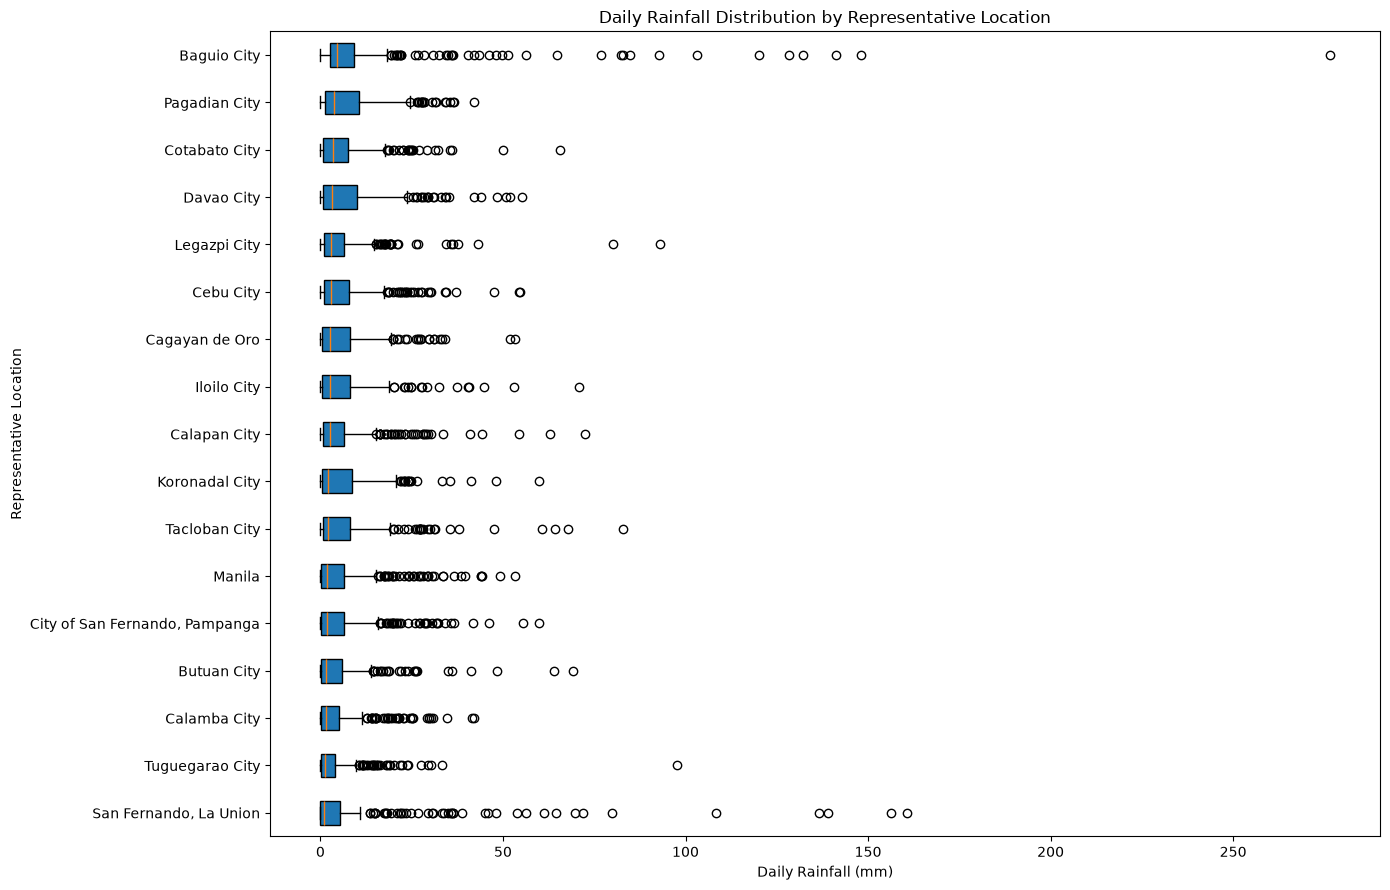

In [77]:
# Box plot of daily rainfall by location

location_order = (
    rainfall_stats
    .sort_values("median_rainfall", ascending=False)["location"]
    .tolist()
)

boxplot_data = [
    df.loc[
        df["location"] == location,
        "precipitation_mm"
    ].dropna().values
    for location in location_order
]

plt.figure(figsize=(14, 9))


plt.boxplot(
    boxplot_data,
    orientation="horizontal",
    patch_artist=True,
    positions=range(len(location_order))
)

plt.yticks(
    range(len(location_order)),
    location_order
)

plt.gca().invert_yaxis()
plt.title("Daily Rainfall Distribution by Representative Location")
plt.xlabel("Daily Rainfall (mm)")
plt.ylabel("Representative Location")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "04_rainfall_distribution_by_location.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Mean vs. Median Daily Rainfall

This comparison examines the difference between mean and median daily rainfall across the 17 representative locations.

A larger gap between these two measures may indicate that relatively few high-rainfall observations are influencing the average. The median provides an additional measure of typical daily rainfall that is less sensitive to extreme values.

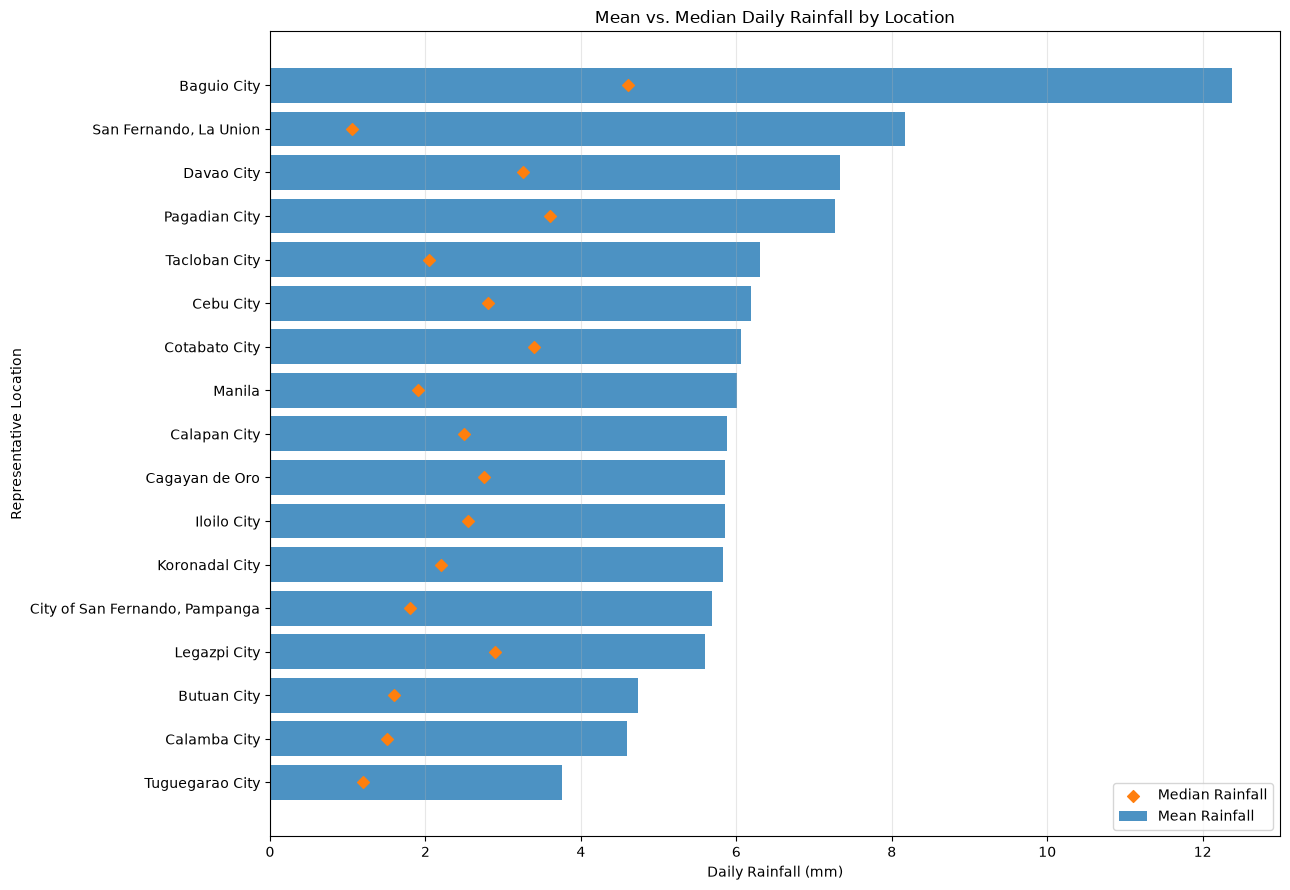

In [78]:
# Compare mean and median rainfall by location

comparison_stats = rainfall_stats.sort_values(
    by="mean_rainfall",
    ascending=True
)

y_positions = range(len(comparison_stats))

plt.figure(figsize=(13, 9))

plt.barh(
    y_positions,
    comparison_stats["mean_rainfall"],
    label="Mean Rainfall",
    alpha=0.8
)

plt.scatter(
    comparison_stats["median_rainfall"],
    y_positions,
    label="Median Rainfall",
    marker="D",
    zorder=3
)

plt.yticks(
    y_positions,
    comparison_stats["location"]
)

plt.xlabel("Daily Rainfall (mm)")
plt.ylabel("Representative Location")

plt.title("Mean vs. Median Daily Rainfall by Location")
plt.legend()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_mean_vs_median_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4. Key Findings and Interpretation

The updated descriptive statistics and visualizations reveal differences in daily rainfall distribution across the 17 representative locations from January 1 to October 31, 2026.

**1. Mean rainfall is consistently higher than median rainfall.**

All 17 locations recorded a mean daily rainfall greater than their median. This indicates that higher-rainfall observations influence average rainfall measurements. The median therefore provides useful additional context when describing typical daily rainfall conditions.

**2. Baguio City recorded the highest mean and maximum rainfall.**

Baguio City recorded a mean daily rainfall of 12.38 mm, a median of 4.60 mm, and a maximum daily observation of 276.40 mm. Its standard deviation of 26.57 mm was also the highest among the 17 locations, indicating substantial variability during the observation period.

**3. San Fernando, La Union also showed a substantial difference between mean and median rainfall.**

Its mean daily rainfall was 8.17 mm, compared with a median of 1.05 mm. Its maximum daily observation reached 160.60 mm, suggesting that higher-rainfall observations contributed considerably to its average.

**4. Rainfall variability differs across locations.**

The standard deviation and box plot demonstrate that daily rainfall distributions are not uniform across the selected locations. Baguio City and San Fernando, La Union showed particularly high variability compared with most other locations.

**5. High average rainfall does not necessarily mean extreme daily rainfall.**

Pagadian City recorded a mean daily rainfall of 7.27 mm but a maximum daily observation of 42.00 mm. This illustrates why average rainfall, rainfall variability, and extreme rainfall frequency should be examined together.

### 5. Conclusion

The analysis supports the recommendation to examine rainfall distributions rather than relying exclusively on average rainfall.

Mean, median, percentiles, standard deviation, and maximum rainfall provide complementary information about rainfall patterns. These measures help identify locations where higher-rainfall observations have a substantial influence on average daily rainfall.

**Limitation:** The analysis covers January 1 to October 31, 2026, using one representative location per administrative region. Results should not be interpreted as complete regional rainfall measurements or as direct indicators of flooding risk.

## M5.2 — Rainfall Segmentation Analysis

### Objective

This section segments daily rainfall observations into five project-defined categories: no rainfall, low, moderate, high, and extreme rainfall.

The analysis compares rainfall category frequency across the 17 representative locations to identify differences in rainfall patterns and the occurrence of extreme rainfall observations.

The segmentation supports comparison of rainfall conditions across locations and provides additional context for stakeholders.

In [79]:
# Create project-defined daily rainfall categories

import numpy as np

conditions = [
    df["precipitation_mm"].eq(0),
    df["precipitation_mm"].gt(0) & df["precipitation_mm"].le(2.5),
    df["precipitation_mm"].gt(2.5) & df["precipitation_mm"].le(7.5),
    df["precipitation_mm"].gt(7.5) & df["precipitation_mm"].lt(50),
    df["precipitation_mm"].ge(50)
]

rainfall_labels = [
    "No rainfall",
    "Low",
    "Moderate",
    "High",
    "Extreme"
]

df["rainfall_category"] = np.select(
    conditions,
    rainfall_labels,
    default="Unclassified"
)

# Check category assignments
print("RAINFALL CATEGORY DISTRIBUTION")
print("-" * 40)

print(
    df["rainfall_category"]
    .value_counts(sort=False)
)

print("\nUnclassified observations:")
print(
    (df["rainfall_category"] == "Unclassified").sum()
)

print("\nExtreme rainfall validation:")
print("From is_extreme:", df["is_extreme"].sum())
print(
    "From rainfall category:",
    (df["rainfall_category"] == "Extreme").sum()
)

display(
    df[
        ["date", "region", "location",
         "precipitation_mm", "rainfall_category"]
    ].head(10)
)

RAINFALL CATEGORY DISTRIBUTION
----------------------------------------
rainfall_category
High           1210
Moderate       1281
Low            1927
No rainfall     696
Extreme          54
Name: count, dtype: int64

Unclassified observations:
0

Extreme rainfall validation:
From is_extreme: 54
From rainfall category: 54


,date,region,location,precipitation_mm,rainfall_category
0,2026-01-01,BARMM,Cotabato City,12.3,High
1,2026-01-02,BARMM,Cotabato City,5.9,Moderate
2,2026-01-03,BARMM,Cotabato City,7.1,Moderate
3,2026-01-04,BARMM,Cotabato City,18.1,High
4,2026-01-05,BARMM,Cotabato City,0.9,Low
5,2026-01-06,BARMM,Cotabato City,13.0,High
6,2026-01-07,BARMM,Cotabato City,0.7,Low
7,2026-01-08,BARMM,Cotabato City,1.3,Low
8,2026-01-09,BARMM,Cotabato City,1.9,Low
9,2026-01-10,BARMM,Cotabato City,5.3,Moderate


### Rainfall Category Frequency by Location

This analysis compares the frequency of each rainfall category across the 17 representative locations.

It identifies which locations recorded more frequent high and extreme rainfall observations and highlights differences in rainfall category composition.

In [80]:
# Create rainfall category frequency by location

category_summary = (
    df.groupby(
        ["region", "location", "rainfall_category"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Ensure consistent category order
category_columns = [
    "No rainfall",
    "Low",
    "Moderate",
    "High",
    "Extreme"
]

category_summary = category_summary[
    ["region", "location"] + category_columns
]

# Add total observations
category_summary["Total observations"] = (
    category_summary[category_columns].sum(axis=1)
)

# Sort by extreme rainfall frequency
category_summary = category_summary.sort_values(
    by="Extreme",
    ascending=False
)

display(category_summary)

rainfall_category,region,location,No rainfall,Low,Moderate,High,Extreme,Total observations
1,CAR,Baguio City,7,68,131,83,15,304
4,Region I (Ilocos),"San Fernando, La Union",90,106,48,48,12,304
12,Region VIII (Eastern Visayas),Tacloban City,22,139,65,74,4,304
2,MIMAROPA,Calapan City,34,121,80,66,3,304
14,Region XI (Davao Region),Davao City,18,124,64,95,3,304
0,BARMM,Cotabato City,26,115,85,76,2,304
10,Region VI (Western Visayas),Iloilo City,40,112,71,79,2,304
13,Region X (Northern Mindanao),Cagayan de Oro,46,103,74,79,2,304
11,Region VII (Central Visayas),Cebu City,24,119,84,75,2,304
16,Region XIII (Caraga),Butuan City,49,123,78,52,2,304


In [81]:
# Export rainfall category summary

category_path = (
    ANALYSIS_DIR / "rainfall_category_by_location.csv"
)

category_summary.to_csv(
    category_path,
    index=False
)

print(f"Saved to: {category_path}")

Saved to: /Users/mark/Github/projects/dep-data-engineering-mark-cabael/output/analysis/rainfall_category_by_location.csv


### Rainfall Category Composition by Location

This visualization compares the distribution of daily rainfall categories across the 17 representative locations.

The stacked horizontal bars show the number of observations classified as no rainfall, low, moderate, high, and extreme rainfall for each location.

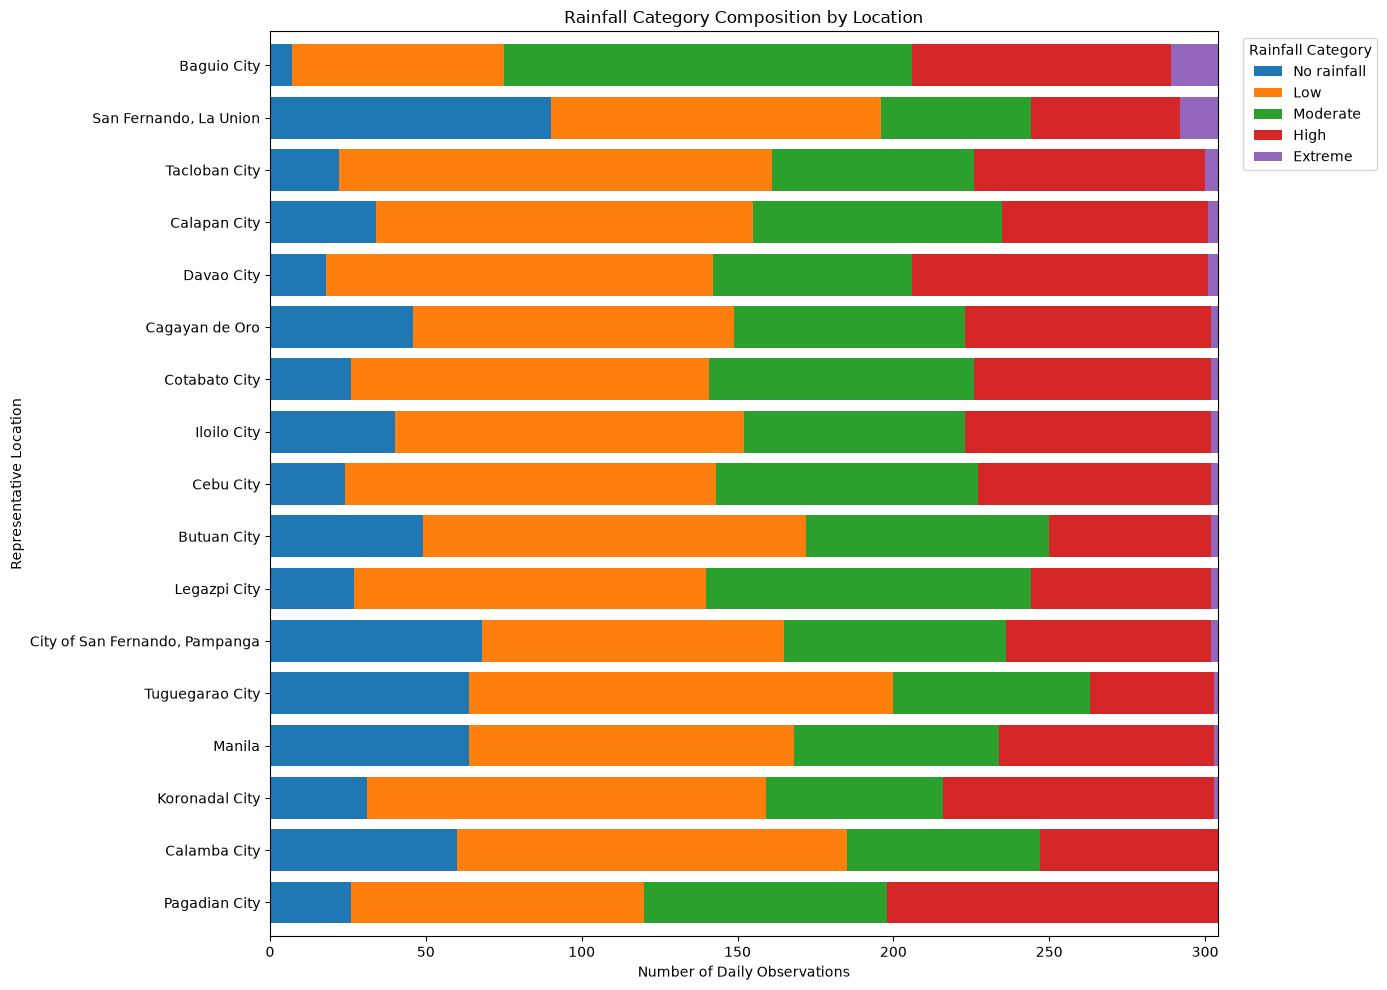

In [82]:
# Visualize rainfall category composition by location

plot_data = category_summary.sort_values(
    by="Extreme",
    ascending=True
).set_index("location")

category_columns = [
    "No rainfall",
    "Low",
    "Moderate",
    "High",
    "Extreme"
]

ax = plot_data[category_columns].plot(
    kind="barh",
    stacked=True,
    figsize=(14, 10),
    width=0.8
)

plt.title("Rainfall Category Composition by Location")
plt.xlabel("Number of Daily Observations")
plt.ylabel("Representative Location")
plt.legend(
    title="Rainfall Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "06_rainfall_category_composition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [83]:
# Calculate high and extreme rainfall frequency

category_summary["High_and_Extreme"] = (
    category_summary["High"]
    + category_summary["Extreme"]
)

category_summary["High_Extreme_Percentage"] = (
    category_summary["High_and_Extreme"]
    / category_summary["Total observations"]
    * 100
)

high_extreme_summary = category_summary[
    [
        "region",
        "location",
        "High",
        "Extreme",
        "High_and_Extreme",
        "High_Extreme_Percentage"
    ]
].sort_values(
    by="High_and_Extreme",
    ascending=False
)

display(high_extreme_summary.round(2))

rainfall_category,region,location,High,Extreme,High_and_Extreme,High_Extreme_Percentage
8,Region IX (Zamboanga Peninsula),Pagadian City,106,0,106,34.87
14,Region XI (Davao Region),Davao City,95,3,98,32.24
1,CAR,Baguio City,83,15,98,32.24
15,Region XII (SOCCSKSARGEN),Koronadal City,87,1,88,28.95
10,Region VI (Western Visayas),Iloilo City,79,2,81,26.64
13,Region X (Northern Mindanao),Cagayan de Oro,79,2,81,26.64
12,Region VIII (Eastern Visayas),Tacloban City,74,4,78,25.66
0,BARMM,Cotabato City,76,2,78,25.66
11,Region VII (Central Visayas),Cebu City,75,2,77,25.33
3,NCR,Manila,69,1,70,23.03


In [84]:
high_extreme_path = (
    ANALYSIS_DIR / "high_extreme_rainfall_by_location.csv"
)

high_extreme_summary.to_csv(
    high_extreme_path,
    index=False
)

print(f"Saved to: {high_extreme_path}")

Saved to: /Users/mark/Github/projects/dep-data-engineering-mark-cabael/output/analysis/high_extreme_rainfall_by_location.csv


### M5.2 — Rainfall Segmentation Findings

The rainfall observations were classified into five project-defined categories: No rainfall (0 mm), Low (>0–2.5 mm), Moderate (>2.5–7.5 mm), High (>7.5–<50 mm), and Extreme (≥50 mm).

The analysis of 5,168 observations from January 1 to October 31, 2026, produced the following findings:

1. **Low rainfall was the most frequent category.** It accounted for 1,927 observations (37.29%), followed by Moderate rainfall with 1,281 observations (24.79%), High rainfall with 1,210 observations (23.41%), No rainfall with 696 observations (13.47%), and Extreme rainfall with 54 observations (1.05%).

2. **Baguio City recorded the highest number of extreme rainfall observations**, with 15 days, followed by San Fernando, La Union, with 12 days. These locations had the highest frequency of observations meeting the project's ≥50 mm extreme rainfall threshold.

3. **Pagadian City recorded the highest combined number of High and Extreme rainfall observations**, with 106 days (34.87% of its observations). However, all 106 observations belonged to the High category, with no Extreme observations.

4. **Davao City and Baguio City both recorded 98 combined High and Extreme observations (32.24%).** Their distributions differed: Davao had 95 High and 3 Extreme observations, while Baguio had 83 High and 15 Extreme observations.

5. **Tuguegarao City had the lowest combined High and Extreme frequency**, with 41 observations (13.49%). Calamba City and Pagadian City recorded no observations in the Extreme category.

### Conclusion

Rainfall segmentation shows that locations can have different rainfall patterns even when their combined High and Extreme frequencies are similar. Pagadian had the highest combined frequency, while Baguio had the highest number of Extreme observations. These distinctions provide useful descriptive information for regional rainfall monitoring and further investigation.

**Limitations:** The categories are project-defined analytical thresholds and are not official PAGASA rainfall classifications. The dataset covers January–October 2026 and uses one representative location per administrative region. The results should not be interpreted as complete regional rainfall measurements, flood predictions, or direct assessments of flood risk.

## M5.3 — Stakeholder KPI Development

### Objective

This section develops key performance indicators (KPIs) to summarize rainfall conditions across the 17 representative locations.

The KPIs provide measurable indicators of accumulated rainfall, average daily rainfall, extreme rainfall frequency, maximum daily rainfall, and rainfall variability.

These indicators are intended to support rainfall monitoring, location comparison, and preliminary planning discussions for local disaster risk reduction and management stakeholders.

In [85]:
# Calculate stakeholder KPIs by location

location_kpis = (
    df.groupby(["region", "location"])
    .agg(
        total_rainfall_mm=(
            "precipitation_mm", "sum"
        ),
        mean_daily_rainfall_mm=(
            "precipitation_mm", "mean"
        ),
        extreme_rainfall_days=(
            "is_extreme", "sum"
        ),
        maximum_daily_rainfall_mm=(
            "precipitation_mm", "max"
        ),
        rainfall_std_dev_mm=(
            "precipitation_mm", "std"
        ),
        observation_count=(
            "precipitation_mm", "count"
        )
    )
    .reset_index()
)

# Sort by total rainfall
location_kpis = location_kpis.sort_values(
    by="total_rainfall_mm",
    ascending=False
)

# Display KPI results
display(location_kpis.round(2))

,region,location,total_rainfall_mm,mean_daily_rainfall_mm,extreme_rainfall_days,maximum_daily_rainfall_mm,rainfall_std_dev_mm,observation_count
1,CAR,Baguio City,3762.3,12.38,15,276.4,26.57,304
4,Region I (Ilocos),"San Fernando, La Union",2484.0,8.17,12,160.6,21.39,304
14,Region XI (Davao Region),Davao City,2230.8,7.34,3,55.2,9.90,304
8,Region IX (Zamboanga Peninsula),Pagadian City,2210.7,7.27,0,42.0,8.54,304
12,Region VIII (Eastern Visayas),Tacloban City,1917.7,6.31,4,83.0,10.70,304
11,Region VII (Central Visayas),Cebu City,1881.5,6.19,2,54.8,8.68,304
0,BARMM,Cotabato City,1843.4,6.06,2,65.5,8.19,304
3,NCR,Manila,1826.7,6.01,1,53.2,9.66,304
2,MIMAROPA,Calapan City,1788.6,5.88,3,72.4,9.39,304
13,Region X (Northern Mindanao),Cagayan de Oro,1779.9,5.85,2,53.3,8.17,304


In [86]:
# Export stakeholder KPI table

kpi_path = (
    ANALYSIS_DIR / "stakeholder_rainfall_kpis.csv"
)

location_kpis.to_csv(
    kpi_path,
    index=False
)

print(f"Stakeholder KPI table saved to: {kpi_path}")

Stakeholder KPI table saved to: /Users/mark/Github/projects/dep-data-engineering-mark-cabael/output/analysis/stakeholder_rainfall_kpis.csv


In [87]:
# Validate stakeholder KPI calculations

print("STAKEHOLDER KPI VALIDATION")
print("-" * 45)

print(
    "Total observations:",
    location_kpis["observation_count"].sum()
)

print(
    "Total rainfall across locations:",
    round(location_kpis["total_rainfall_mm"].sum(), 2),
    "mm"
)

print(
    "Total extreme rainfall days:",
    location_kpis["extreme_rainfall_days"].sum()
)

print(
    "Locations included:",
    location_kpis["location"].nunique()
)

print("\nMissing KPI values:")
print(
    location_kpis.isnull().sum()
)

STAKEHOLDER KPI VALIDATION
---------------------------------------------
Total observations: 5168
Total rainfall across locations: 32684.0 mm
Total extreme rainfall days: 54
Locations included: 17

Missing KPI values:
region                       0
location                     0
total_rainfall_mm            0
mean_daily_rainfall_mm       0
extreme_rainfall_days        0
maximum_daily_rainfall_mm    0
rainfall_std_dev_mm          0
observation_count            0
dtype: int64


In [88]:
# Investigate extreme rainfall count mismatch

print("EXTREME RAINFALL DIAGNOSTICS")
print("-" * 45)

# Recalculate extreme rainfall directly from precipitation
expected_extreme = df["precipitation_mm"] >= 50

# Inspect existing column
print("Existing is_extreme data type:")
print(df["is_extreme"].dtype)

print("\nExisting is_extreme values:")
print(df["is_extreme"].value_counts(dropna=False))

# Convert existing values safely
existing_extreme = (
    df["is_extreme"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "1": True,
        "false": False,
        "0": False
    })
)

print("\nExtreme count from existing column:")
print(existing_extreme.sum())

print("\nExtreme count from rainfall >= 50 mm:")
print(expected_extreme.sum())

# Identify inconsistent records
mismatches = df[
    existing_extreme.ne(expected_extreme)
]

print("\nNumber of mismatched observations:")
print(len(mismatches))

display(
    mismatches[
        [
            "date",
            "region",
            "location",
            "precipitation_mm",
            "is_extreme"
        ]
    ]
)

EXTREME RAINFALL DIAGNOSTICS
---------------------------------------------
Existing is_extreme data type:
bool

Existing is_extreme values:
is_extreme
False    5114
True       54
Name: count, dtype: int64

Extreme count from existing column:
54

Extreme count from rainfall >= 50 mm:
54

Number of mismatched observations:
0


,date,region,location,precipitation_mm,is_extreme


In [89]:
# Generate monthly stakeholder KPIs

# Ensure date is in datetime format
df["date"] = pd.to_datetime(df["date"])

# Create monthly grouping column
df["month"] = df["date"].dt.to_period("M").astype(str)

# Calculate monthly KPIs across all 17 locations
monthly_kpis = (
    df.groupby("month")
    .agg(
        total_rainfall_mm=("precipitation_mm", "sum"),
        mean_daily_rainfall_mm=("precipitation_mm", "mean"),
        extreme_rainfall_observations=("is_extreme", "sum"),
        high_extreme_observations=(
            "rainfall_category",
            lambda x: x.isin(["High", "Extreme"]).sum()
        ),
        observation_count=("precipitation_mm", "count")
    )
    .reset_index()
)

# Save monthly KPI results
monthly_kpis.to_csv(
    ANALYSIS_DIR / "monthly_stakeholder_kpis.csv",
    index=False
)

# Display results
print("MONTHLY STAKEHOLDER KPIs")
print("-" * 50)

display(monthly_kpis)

print("\nVALIDATION")
print("-" * 50)
print("Months included:", monthly_kpis["month"].nunique())
print("Total observations:", monthly_kpis["observation_count"].sum())
print(
    "Total rainfall:",
    round(monthly_kpis["total_rainfall_mm"].sum(), 2),
    "mm"
)
print(
    "Total extreme observations:",
    monthly_kpis["extreme_rainfall_observations"].sum()
)

MONTHLY STAKEHOLDER KPIs
--------------------------------------------------


,month,total_rainfall_mm,mean_daily_rainfall_mm,extreme_rainfall_observations,high_extreme_observations,observation_count
0,2026-01,2341.6,4.443264,5,80,527
1,2026-02,3296.0,6.924370,10,120,476
2,2026-03,1094.6,2.077040,0,35,527
3,2026-04,791.0,1.550980,0,26,510
4,2026-05,2868.7,5.443454,2,124,527
5,2026-06,3041.4,5.963529,1,135,510
6,2026-07,4813.4,9.133586,6,220,527
7,2026-08,6402.9,12.149715,27,161,527
8,2026-09,4275.6,8.383529,3,187,510
9,2026-10,3758.8,7.132448,0,176,527



VALIDATION
--------------------------------------------------
Months included: 10
Total observations: 5168
Total rainfall: 32684.0 mm
Total extreme observations: 54


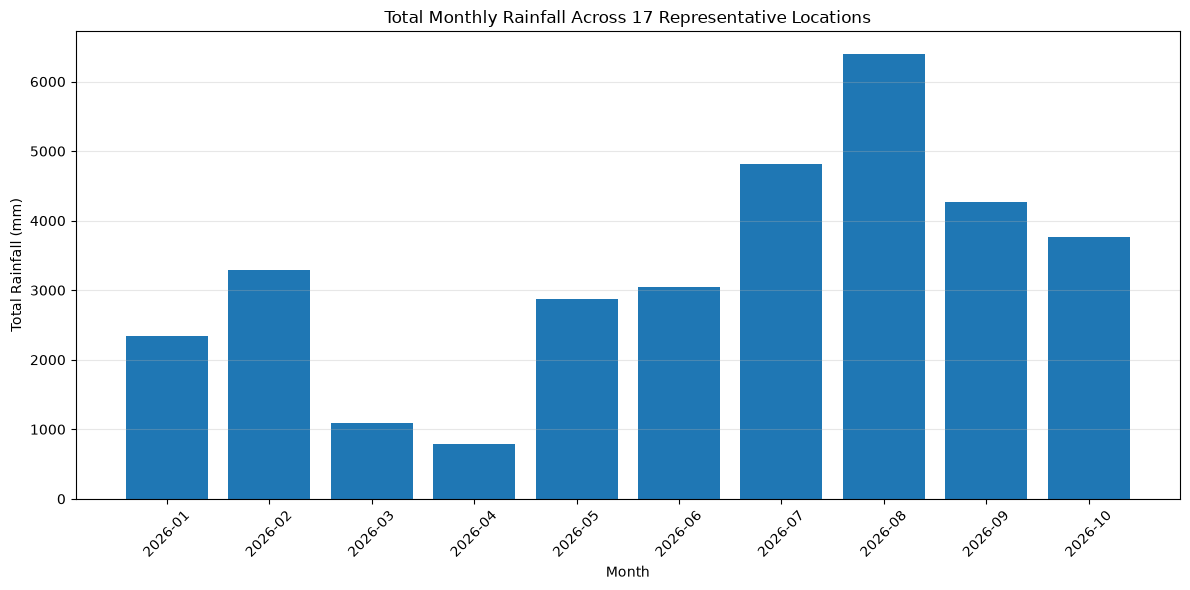

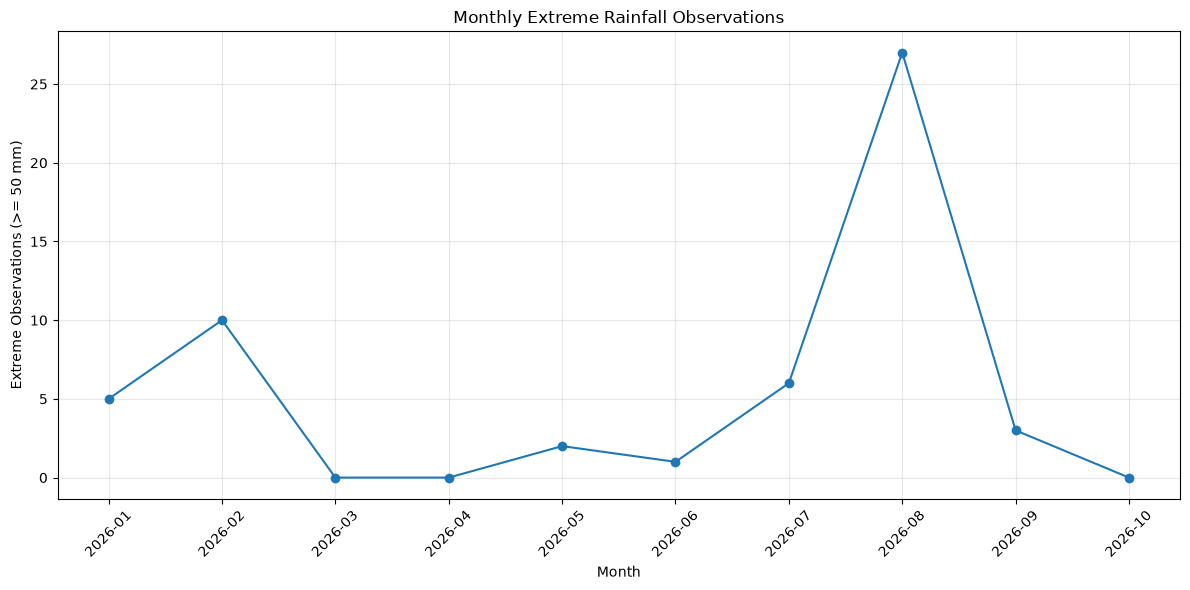

Monthly trend charts saved successfully.


In [90]:
# Monthly KPI trend visualizations

import matplotlib.pyplot as plt

# Ensure chronological ordering
monthly_kpis = monthly_kpis.sort_values("month")

# Chart 1: Total monthly rainfall
plt.figure(figsize=(12, 6))

plt.bar(
    monthly_kpis["month"],
    monthly_kpis["total_rainfall_mm"]
)

plt.title("Total Monthly Rainfall Across 17 Representative Locations")
plt.xlabel("Month")
plt.ylabel("Total Rainfall (mm)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "07_monthly_total_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Chart 2: Monthly extreme rainfall observations
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_kpis["month"],
    monthly_kpis["extreme_rainfall_observations"],
    marker="o"
)

plt.title("Monthly Extreme Rainfall Observations")
plt.xlabel("Month")
plt.ylabel("Extreme Observations (>= 50 mm)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "08_monthly_extreme_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Monthly trend charts saved successfully.")

### M5.3 — Stakeholder KPI Findings

The monthly stakeholder KPI analysis covered January to October 2026, using 5,168 daily rainfall observations across 17 representative locations.

1. **August recorded the highest total rainfall**, reaching 6,402.9 mm across all locations, with a mean daily rainfall of 12.15 mm per location-day.

2. **August also recorded the highest number of extreme rainfall observations**, with 27 observations, representing 50% of the 54 extreme observations recorded during the study period.

3. **July recorded the highest combined number of High and Extreme rainfall observations**, with 220 observations. September followed with 187, while October recorded 176.

4. **March and April had the lowest mean daily rainfall**, at 2.08 mm and 1.55 mm, respectively, indicating comparatively lower rainfall during these months in the selected locations.

5. **Monthly rainfall patterns varied throughout the observation period.** Rainfall increased from May through August, peaked in August, and declined in September and October. However, High and Extreme observations remained relatively frequent in the latter months.

### Conclusion

The monthly KPIs identify August as the period with the highest accumulated rainfall and extreme rainfall frequency, while July had the highest combined frequency of High and Extreme observations. These findings can help stakeholders identify periods that may warrant closer rainfall monitoring.

**Limitations:** These results describe the selected representative locations from January to October 2026. They do not establish future rainfall patterns, predict flooding, or represent complete rainfall measurements for every area within each administrative region.

# Stakeholder Brief: Philippine Regional Rainfall Analysis

**Reporting Period:** January 1 – October 31, 2026  
**Data Coverage:** 17 representative locations across the Philippines  
**Data Source:** Open-Meteo Historical Weather API

## 1. Overview

This analysis examines daily rainfall observations from 17 representative locations across the Philippines to identify rainfall patterns, heavier rainfall events, and months that may warrant closer monitoring.

The analysis aims to provide supporting information for local disaster risk reduction offices, local government units, and regional planning teams.

## 2. Key Findings

- **August recorded the highest combined rainfall**, with 6,402.9 mm across the 17 representative locations.
- **July recorded the second-highest combined rainfall**, with 4,813.4 mm.
- **August had the most extreme rainfall observations**, recording 27 observations at or above the project's 50 mm daily threshold.
- **Baguio City recorded the highest number of extreme rainfall observations**, with 15, followed by San Fernando, La Union, with 12.
- A total of **54 extreme rainfall observations** were identified among 5,168 location-day observations.
- **July recorded the highest combined number of High and Extreme observations**, with 220.

## 3. Operational Implications

The findings suggest that July and August deserve particular attention when reviewing rainfall monitoring and preparedness activities.

Locations with higher observed extreme rainfall frequency, particularly Baguio City and San Fernando, La Union, may warrant closer examination using additional local rainfall records.

These results can support preliminary monitoring priorities, resource planning, and further investigation by local disaster risk reduction teams.

## 4. Recommendations

1. Strengthen rainfall monitoring during months with higher observed rainfall.
2. Review local historical rainfall records to validate patterns at the municipal and provincial levels.
3. Combine rainfall observations with river levels, drainage conditions, topography, and historical flood records before conducting flood-risk assessments.
4. Expand data coverage to additional monitoring stations to improve regional representation.

## 5. Data Limitations

This analysis uses one representative location per region and covers January to October 2026. Therefore, the findings do not represent complete rainfall measurements for entire regions or establish long-term seasonal patterns.

The 50 mm extreme rainfall threshold is a project-defined analytical threshold and is not presented as an official PAGASA classification. Rainfall observations alone cannot determine or predict flooding.

**Conclusion:** The analysis provides an initial, data-driven overview of rainfall patterns across selected Philippine locations. Further validation with local monitoring stations and additional environmental data is recommended before using these findings for operational decisions.